# 5. Anomaly Detection (system 4)

The power models of notebooks 3A-4 describe **normal** behaviour: given the irradiance and the module temperature, the best endogenous model returns the power the plant should produce. This notebook uses that expected power to find anomalies, and compares three detectors:

| Detector | Idea | Learns from |
|---|---|---|
| Rule (baseline) | `is_fault` of notebook 1: strong sun, power below 0.5 × k × irradiance | nothing (fixed physics rule) |
| Residual | the actual power is far from the expected power for 15 minutes (two-sided) | thresholds from the **training period** normal rows |
| Isolation Forest | the point is easy to isolate in (power, irradiance, module temperature, residual) | training-period rows, **never** the labels |

**Avoiding circular evaluation.** The rule labels cannot judge the rule, and a residual detector scored against labels made with the same idea would look perfect without proving anything. So:

- On the **real data** the rule labels are used as the reference only for **full outages** (sun up, power near zero), where they are unambiguous.
- **Partial losses** and **sensor faults** have no labels in the data. They are **injected synthetically** into normal test days (known start, end and size), so the recall of every detector, the rule included, can be measured exactly; the false-alarm rate is measured on untouched normal test days.

Sections: 5.0 setup, 5.1 residuals of the best model (F1), 5.2 rule baseline (F2), 5.3 residual detector (F3), 5.4 Isolation Forest (F4), 5.5 evaluation by anomaly type (F5), 5.6 agreement analysis (F6), 5.7 example events (F7), 5.8 summary for notebook 6.

## 5.0 Setup

In [1]:
import json
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest

PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "data" / "cleaned").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the thesis project root.")

SYSTEM_ID = 4
TARGET = "dc_power__314"
IRRADIANCE = "poa_irradiance__313"
MODULE_TEMP = "module_temp_1__321"
FEATURES = [IRRADIANCE, MODULE_TEMP]  # inputs of the endogenous models (notebook 2, pipeline 8A)

METRICS_DIR = PROJECT_ROOT / "artifacts" / "metrics"
MODELS_DIR = PROJECT_ROOT / "artifacts" / "models"
MODEL_SLUGS = {"Linear Regression": "linear_regression", "Decision Tree": "decision_tree",
               "Random Forest": "random_forest", "MLP": "mlp", "XGBoost": "xgboost"}
DETECTOR_COLORS = {"rule": "tab:red", "residual_low": "tab:purple", "residual_high": "tab:orange",
                   "iforest": "tab:green"}
print(f"Project root: {PROJECT_ROOT}")

Project root: /home/raul/Desktop/solar-data-all/thesis


### Load the data, the reference model and the train/test periods

All daylight rows of notebook 1 are used, normal and flagged. The reference model is the endogenous model chosen in notebook 4 (section 4.8), with its scaler from notebook 2. The training period is the one the model was trained on; thresholds are learned there and everything is evaluated on the test period.

In [2]:
data = pd.read_csv(PROJECT_ROOT / "data" / "cleaned" / f"system_{SYSTEM_ID}_cleaned.csv",
                   parse_dates=["datetime"], low_memory=False)
data = data.set_index("datetime").sort_index()
assert data.index.is_unique

best_models = pd.read_csv(METRICS_DIR / f"system_{SYSTEM_ID}_eval_best_models.csv", index_col="task")
REFERENCE_MODEL = best_models.loc["Estimation, endogenous", "chosen"]
with (MODELS_DIR / f"system_{SYSTEM_ID}_endogenous_{MODEL_SLUGS[REFERENCE_MODEL]}.pkl").open("rb") as file:
    model = pickle.load(file)
with (MODELS_DIR / f"scaler_group_{SYSTEM_ID}_endogenous.pkl").open("rb") as file:
    scaler = pickle.load(file)

config_summary = pd.read_csv(METRICS_DIR / f"system_{SYSTEM_ID}_feature_configs.csv", index_col="config")
SPLIT_TIME = pd.Timestamp(config_summary.loc["endogenous", "test_start"])


def is_test_time(index):
    """Test period of the power models: everything from the first test timestamp on."""
    return np.asarray(index >= SPLIT_TIME)


data["test"] = is_test_time(data.index)
print(f"Rows: {len(data):,} ({int(data['is_fault'].sum()):,} flagged by the rule)")
print(f"Reference model: endogenous {REFERENCE_MODEL}")
display(data.groupby("test")["is_fault"].agg(["size", "sum", "mean"])
        .rename(index={False: "train period", True: "test period"},
                columns={"size": "rows", "sum": "rule flags", "mean": "rule share"}))

Rows: 1,416,630 (92,307 flagged by the rule)
Reference model: endogenous MLP


,rows,rule flags,rule share
test,,,
train period,1133131,73673,0.065017
test period,283499,18634,0.065729


## 5.1 Residuals of the reference model (F1)

For every row the model returns the **expected power** from the irradiance and module temperature. The residual is `actual − expected`. To compare morning and noon, it is divided by the expected power, with a floor of `MIN_EXPECTED_SHARE × P_REF` (`P_REF` = 99th percentile of the training power, close to the rated power), so that tiny expected values at low light do not blow it up:

`relative residual = (actual − expected) / max(expected, MIN_EXPECTED_SHARE × P_REF)`

A 30% partial loss gives about −0.3, a full outage about −1, and an irradiance sensor that reads 30% too low gives about +0.4 (the model expects too little). Single minutes are noisy (clouds move faster than the module temperature follows), so the detector uses the **trailing 15-minute median** (`SMOOTHING_WINDOW`); it only looks back, so it could run in real time.

In [3]:
# Residual settings.
MIN_EXPECTED_SHARE = 0.10
SMOOTHING_WINDOW = "15min"

train_normal = ~data["test"] & ~data["is_fault"]
P_REF = float(data.loc[train_normal, TARGET].quantile(0.99))


def add_residuals(frame):
    """Expected power of the reference model and the (smoothed) relative residual."""
    frame = frame.copy()
    inputs = pd.DataFrame(scaler.transform(frame[FEATURES]), index=frame.index, columns=FEATURES)
    frame["expected"] = model.predict(inputs)
    frame["residual"] = frame[TARGET] - frame["expected"]
    frame["rel_residual"] = frame["residual"] / np.maximum(frame["expected"], MIN_EXPECTED_SHARE * P_REF)
    frame["rel_residual_smooth"] = frame["rel_residual"].rolling(SMOOTHING_WINDOW, min_periods=1).median()
    return frame


data = add_residuals(data)
print(f"P_REF = {P_REF:,.1f} W")
display(data.groupby(["test", "is_fault"])[["residual", "rel_residual", "rel_residual_smooth"]]
        .median().round(3).rename_axis(["test period", "rule flag"]))

P_REF = 1,012.1 W


residual  rel_residual  rel_residual_smooth
test period rule flag                                             
False       False         3.535         0.008                0.008
            True       -140.137        -0.866               -0.856
True        False        -6.094        -0.012               -0.011
            True       -100.795        -0.782               -0.762

## 5.2 Rule baseline (F2)

The rule of notebook 1 is the simplest detector: irradiance above 50 W/m² and power below `FAULT_RATIO × k × irradiance`. `k` (median power / irradiance ratio above 200 W/m²) is recomputed here exactly as in notebook 1, and the check confirms that the function reproduces the saved `is_fault` column. The function is needed because the rule must also be applied to the synthetic data in 5.5.

In [4]:
# Rule settings (same values as notebook 1).
K_MIN_IRRADIANCE_W_M2 = 200.0
FAULT_MIN_IRRADIANCE_W_M2 = 50.0
FAULT_RATIO = 0.5

ratio = data[TARGET] / data[IRRADIANCE]
K = float(ratio[data[IRRADIANCE].gt(K_MIN_IRRADIANCE_W_M2)].median())


def rule_flags(frame):
    irradiance = frame[IRRADIANCE]
    return irradiance.gt(FAULT_MIN_IRRADIANCE_W_M2) & frame[TARGET].lt(FAULT_RATIO * K * irradiance)


assert rule_flags(data).eq(data["is_fault"]).all()
print(f"k = {K:.4f} W per W/m²; rule reproduces is_fault on all {len(data):,} rows")

k = 0.8771 W per W/m²; rule reproduces is_fault on all 1,416,630 rows


## 5.3 Residual detector (F3)

Two thresholds on the smoothed relative residual, learned on the **normal rows of the training period** only: `median ± RESIDUAL_MAD_FACTOR × σ`, with σ = 1.4826 × MAD (the median absolute deviation, a robust standard deviation). A first version used the 0.5% / 99.5% quantiles instead; the low quantile landed at about −0.43 because the "normal" rows still contain unflagged partial losses down to the rule boundary (ratio 0.5), so the detector could not see any loss smaller than ~45%. The MAD describes the bulk of normal operation and is not pulled by that tail. The factor sets the trade-off between false alarms and sensitivity; 5.5.3 shows it for several values. Low flags mean **under-production** (outage, partial loss, or an irradiance sensor reading too high); high flags mean **over-production** relative to the irradiance, which in practice points to an irradiance sensor reading too low (dirty, shaded or misaligned sensor).

In [5]:
# Residual detector settings.
RESIDUAL_MAD_FACTOR = 5.0

normal_smooth = data.loc[train_normal, "rel_residual_smooth"]
RESIDUAL_CENTER = float(normal_smooth.median())
RESIDUAL_SIGMA = float(1.4826 * (normal_smooth - RESIDUAL_CENTER).abs().median())
LOW_THRESHOLD = RESIDUAL_CENTER - RESIDUAL_MAD_FACTOR * RESIDUAL_SIGMA
HIGH_THRESHOLD = RESIDUAL_CENTER + RESIDUAL_MAD_FACTOR * RESIDUAL_SIGMA


def residual_flags(frame):
    smooth = frame["rel_residual_smooth"]
    return smooth.lt(LOW_THRESHOLD), smooth.gt(HIGH_THRESHOLD)


print(f"Normal training residual: median {RESIDUAL_CENTER:+.3f}, robust sigma {RESIDUAL_SIGMA:.3f}")
print(f"Thresholds on the smoothed relative residual: low {LOW_THRESHOLD:+.3f}, high {HIGH_THRESHOLD:+.3f}")
print(f"Normal training rows outside the thresholds: "
      f"{100 * (normal_smooth.lt(LOW_THRESHOLD) | normal_smooth.gt(HIGH_THRESHOLD)).mean():.2f}%")

Normal training residual: median +0.008, robust sigma 0.044
Thresholds on the smoothed relative residual: low -0.210, high +0.226
Normal training rows outside the thresholds: 4.63%


## 5.4 Isolation Forest (F4)

An unsupervised detector: Isolation Forest builds random trees and scores how quickly a point is isolated; rare combinations are isolated fast. Inputs: power, irradiance, module temperature and the (point) relative residual. It is fitted on a random sample of **all training-period rows** (normal and flagged, labels not used) and flags the `IF_CONTAMINATION` share of the most isolated points. The share of real anomalies is unknown in an unsupervised setting; 5% is a common prior and is reported, not tuned on the labels.

In [6]:
# Isolation Forest settings.
IF_FEATURES = [TARGET, IRRADIANCE, MODULE_TEMP, "rel_residual"]
IF_CONTAMINATION = 0.05
IF_TRAIN_SAMPLE = 200_000
IF_N_ESTIMATORS = 200
IF_SEED = 0

train_rows = data.loc[~data["test"], IF_FEATURES]
iforest = IsolationForest(n_estimators=IF_N_ESTIMATORS, contamination=IF_CONTAMINATION,
                          random_state=IF_SEED, n_jobs=-1)
iforest.fit(train_rows.sample(n=min(IF_TRAIN_SAMPLE, len(train_rows)), random_state=IF_SEED))


def iforest_flags(frame):
    return pd.Series(iforest.predict(frame[IF_FEATURES]) == -1, index=frame.index)


def detect(frame):
    """Boolean flags of every detector for an already residual-scored frame."""
    low, high = residual_flags(frame)
    return pd.DataFrame({"rule": rule_flags(frame), "residual_low": low, "residual_high": high,
                         "iforest": iforest_flags(frame)})


flags = detect(data)
flags["residual"] = flags["residual_low"] | flags["residual_high"]
display(flags.groupby(data["test"]).mean().round(4)
        .rename(index={False: "train period", True: "test period"}))

,rule,residual_low,residual_high,iforest,residual
test,,,,,
train period,0.0650,0.1011,0.0043,0.0501,0.1054
test period,0.0657,0.1047,0.0050,0.0451,0.1097


## 5.5 Evaluation by anomaly type (F5)

### 5.5.1 Real data: full outages

On the real test period the rule labels are trusted only for **full outages**: rule rows where the power is below `FULL_OUTAGE_SHARE × k × irradiance` (practically zero). For each detector: how many test rows it flags, the recall on full outages and on all rule rows, and how many of its flags lie **outside** the rule (these are not necessarily false alarms: they are the candidates for partial losses and sensor faults, examined in 5.6). Events group flagged minutes less than 20 minutes apart, as in notebook 1.

In [7]:
# Full outage definition and event grouping.
FULL_OUTAGE_SHARE = 0.1
EVENT_GAP = pd.Timedelta("20min")


def to_events(flag):
    """Start, end, duration (min) and size of runs of flagged rows less than EVENT_GAP apart."""
    times = flag.index[flag.to_numpy()].to_series()
    if times.empty:
        return pd.DataFrame(columns=["start", "end", "minutes", "rows"])
    run = times.diff().gt(EVENT_GAP).cumsum()
    events = times.groupby(run).agg(["min", "max", "size"])
    events.columns = ["start", "end", "rows"]
    events["minutes"] = (events["end"] - events["start"]).dt.total_seconds() / 60 + 1
    return events.reset_index(drop=True)


test = data.loc[data["test"]]
test_flags = flags.loc[data["test"]]
full_outage = test["is_fault"] & test[TARGET].lt(FULL_OUTAGE_SHARE * K * test[IRRADIANCE])

real_rows = []
for detector in ("rule", "residual_low", "residual_high", "residual", "iforest"):
    flag = test_flags[detector]
    events = to_events(flag)
    real_rows.append({
        "detector": detector,
        "flagged_rows": int(flag.sum()),
        "flagged_share_%": 100 * flag.mean(),
        "recall_full_outage_%": 100 * flag[full_outage].mean(),
        "recall_rule_rows_%": 100 * flag[test["is_fault"]].mean(),
        "flags_outside_rule_%": 100 * (flag & ~test["is_fault"]).sum() / max(flag.sum(), 1),
        "events": len(events),
        "median_event_min": events["minutes"].median() if len(events) else np.nan,
    })
real_table = pd.DataFrame(real_rows).set_index("detector")
print(f"Test period: {len(test):,} rows, {int(test['is_fault'].sum()):,} rule rows, "
      f"{int(full_outage.sum()):,} full-outage rows")
display(real_table.round(2))

Test period: 283,499 rows, 18,634 rule rows, 10,776 full-outage rows


,flagged_rows,flagged_share_%,recall_full_outage_%,recall_rule_rows_%,flags_outside_rule_%,events,median_event_min
detector,,,,,,,
rule,18634,6.57,100.00,100.00,0.00,452,13.0
residual_low,29673,10.47,99.49,95.48,40.04,486,34.5
residual_high,1427,0.50,0.00,0.00,100.00,23,28.0
residual,31100,10.97,99.49,95.48,42.79,507,34.0
iforest,12797,4.51,78.29,58.28,15.14,323,8.0


### 5.5.2 Synthetic anomalies: partial losses and sensor faults

Real partial losses and sensor faults have no labels, so they are **injected** into the test period, on days whose 09:30-14:30 window has no rule flag (clean days). `FALSE_ALARM_DAY_SHARE` of the clean days never receive an event; the false alarms are measured on them. Each event lasts `EVENT_MINUTES` and starts at a random time between 10:00 and 12:00; every type gets up to `N_EVENTS_PER_TYPE` events (fixed seed). A day receives at most one event per injected copy of the test period (a **round**); when there are fewer days than events, further rounds reuse the days with new start times and sizes, up to `MAX_ROUNDS` (system 4 has enough days for one round).

| Type | What is changed | Size |
|---|---|---|
| full outage | power set to 0 | — |
| partial loss | power × (1 − loss) | loss drawn uniformly from 10-40% (shading, soiling, snow, a failed string) |
| sensor fault | irradiance × (1 − error), power unchanged | error drawn uniformly from 20-40% (dirty or misaligned sensor reading too low) |

The modified rows go through the same residual pipeline and every detector. An event counts as detected when at least `MIN_EVENT_COVERAGE` of its minutes are flagged; row recall is also reported. The **false-alarm rate** is the share of flagged normal rows on the reserved clean days. It is an upper bound: those days can still contain real, unlabelled partial losses.

In [8]:
# Injection settings.
EVENT_MINUTES = 120
N_EVENTS_PER_TYPE = 100
MAX_ROUNDS = 10
FALSE_ALARM_DAY_SHARE = 0.25
MIN_EVENT_COVERAGE = 0.5
MIN_DAY_ROWS = 300
INJECTION_SEED = 42
ANOMALY_TYPES = ["full outage", "partial loss", "sensor fault"]
EVENT_LENGTH = pd.Timedelta(minutes=EVENT_MINUTES)

rng = np.random.default_rng(INJECTION_SEED)
day = test.index.normalize()
minute_of_day = test.index.hour * 60 + test.index.minute
midday = (minute_of_day >= 9 * 60 + 30) & (minute_of_day < 14 * 60 + 30)
day_rows = test.groupby(day).size()
midday_faults = test.loc[midday, "is_fault"].groupby(day[midday]).sum().reindex(day_rows.index, fill_value=0)
clean_days = day_rows.index[day_rows.ge(MIN_DAY_ROWS) & midday_faults.eq(0)]

# A share of the clean days never receives an event: the false alarms are measured there.
shuffled_days = rng.permutation(clean_days)
n_reserved = max(1, round(FALSE_ALARM_DAY_SHARE * len(shuffled_days)))
reserved_days, injection_days = shuffled_days[:n_reserved], shuffled_days[n_reserved:]
n_events = min(N_EVENTS_PER_TYPE, len(injection_days) * MAX_ROUNDS // len(ANOMALY_TYPES))
n_total = n_events * len(ANOMALY_TYPES)
event_days = np.concatenate([rng.permutation(injection_days)
                             for _ in range(int(np.ceil(n_total / len(injection_days))))])[:n_total]

event_rows = []
for number, event_day in enumerate(event_days):
    kind = ANOMALY_TYPES[number % len(ANOMALY_TYPES)]
    size = 1.0 if kind == "full outage" else rng.uniform(0.10, 0.40) if kind == "partial loss" else rng.uniform(0.20, 0.40)
    start = event_day + pd.Timedelta(hours=10) + pd.Timedelta(minutes=int(rng.integers(0, 121)))
    event_rows.append({"event": number, "round": number // len(injection_days), "type": kind,
                       "day": event_day, "start": start, "size": size})
events_injected = pd.DataFrame(event_rows)

# One injected copy of the test period per round (a day gets at most one event per round).
base = test.drop(columns=["expected", "residual", "rel_residual", "rel_residual_smooth"])
event_frames = []
for _, round_events in events_injected.groupby("round"):
    injected = base.copy()
    event_id = pd.Series(-1, index=injected.index)
    for row in round_events.itertuples():
        window = (injected.index >= row.start) & (injected.index < row.start + EVENT_LENGTH)
        column = IRRADIANCE if row.type == "sensor fault" else TARGET
        injected.loc[window, column] *= 1 - row.size
        event_id[window] = row.event
    injected = add_residuals(injected)
    injected_flags = detect(injected)
    injected_flags["residual"] = injected_flags["residual_low"] | injected_flags["residual_high"]
    in_event = event_id.ge(0)
    event_frames.append(injected_flags[in_event].assign(
        event=event_id[in_event], rel_residual_smooth=injected.loc[in_event, "rel_residual_smooth"]))
event_flags = pd.concat(event_frames)
event_flags["type"] = event_flags["event"].map(events_injected.set_index("event")["type"])
events_injected = events_injected.join(event_flags.groupby("event").size().rename("rows"), on="event")

untouched = day.isin(reserved_days) & ~test["is_fault"].to_numpy()
untouched_flags = test_flags[untouched]
untouched_smooth = test.loc[untouched, "rel_residual_smooth"]
print(f"{n_events} events per type: {len(injection_days)} injection days x "
      f"{events_injected['round'].nunique()} round(s); {len(reserved_days)} clean days "
      f"({len(untouched_flags):,} rows) kept for false alarms; {len(clean_days)} clean test days in total")

100 events per type: 322 injection days x 1 round(s); 107 clean days (62,103 rows) kept for false alarms; 429 clean test days in total


In [9]:
DETECTORS = ["rule", "residual", "iforest"]
coverage = event_flags.groupby("event")[DETECTORS].mean()
events_injected = events_injected.join(coverage.add_prefix("coverage_"), on="event")

synthetic_rows = []
for kind in ANOMALY_TYPES:
    kind_events = events_injected[events_injected["type"].eq(kind)]
    for detector in DETECTORS:
        synthetic_rows.append({"type": kind, "detector": detector,
                               "event_recall_%": 100 * kind_events[f"coverage_{detector}"].ge(MIN_EVENT_COVERAGE).mean(),
                               "row_recall_%": 100 * event_flags.loc[event_flags["type"].eq(kind), detector].mean()})
for detector in DETECTORS:
    synthetic_rows.append({"type": "false alarms (clean days)", "detector": detector,
                           "event_recall_%": np.nan, "row_recall_%": 100 * untouched_flags[detector].mean()})
synthetic_table = pd.DataFrame(synthetic_rows).set_index(["type", "detector"])
display(synthetic_table.unstack("detector").round(1))

# Partial losses: recall by loss size.
partial = events_injected[events_injected["type"].eq("partial loss")].copy()
partial["loss"] = pd.cut(partial["size"], [0.10, 0.20, 0.30, 0.40], labels=["10-20%", "20-30%", "30-40%"],
                         include_lowest=True)
partial_by_size = partial.groupby("loss", observed=True).apply(
    lambda g: pd.Series({detector: 100 * g[f"coverage_{detector}"].ge(MIN_EVENT_COVERAGE).mean()
                         for detector in DETECTORS} | {"events": len(g)}))
print("Partial losses: event recall (%) by loss size")
display(partial_by_size.round(1))

event_recall_%                 row_recall_%  \
detector                         iforest residual   rule      iforest   
type                                                                    
false alarms (clean days)            NaN      NaN    NaN          0.8   
full outage                         99.0    100.0  100.0         98.3   
partial loss                        18.0     58.0    0.0         21.0   
sensor fault                        19.0     97.0    0.0         22.7   

                                           
detector                  residual   rule  
type                                       
false alarms (clean days)      4.9    0.0  
full outage                   94.2  100.0  
partial loss                  56.0    0.0  
sensor fault                  90.5    0.0

Partial losses: event recall (%) by loss size


,rule,residual,iforest,events
loss,,,,
10-20%,0.0,0.0,0.0,35.0
20-30%,0.0,81.6,28.9,38.0
30-40%,0.0,100.0,25.9,27.0


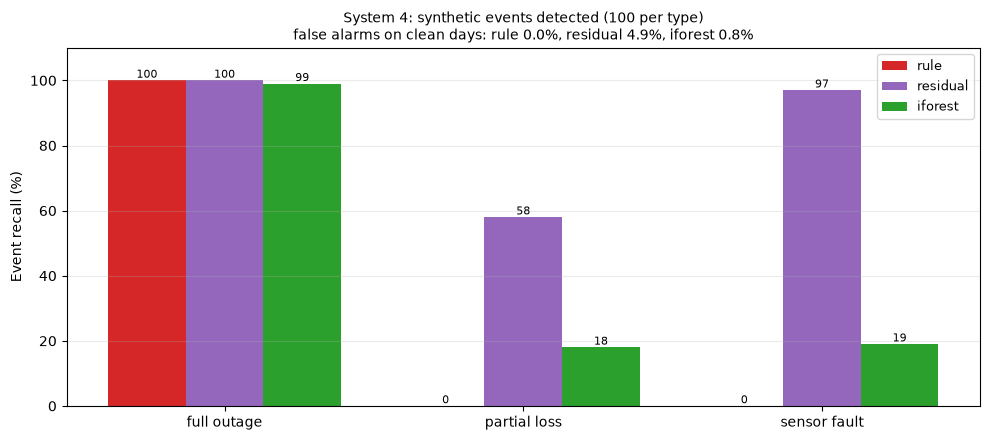

Saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/metrics/system_4_anomaly_recall_by_type.png


In [10]:
RECALL_PLOT_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_anomaly_recall_by_type.png"
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_table = synthetic_table["event_recall_%"].unstack("detector").loc[ANOMALY_TYPES, DETECTORS]
width = 0.26
positions = np.arange(len(ANOMALY_TYPES))
colors = {"rule": "tab:red", "residual": "tab:purple", "iforest": "tab:green"}
for offset, detector in zip((-width, 0, width), DETECTORS):
    bars = ax.bar(positions + offset, plot_table[detector], width, color=colors[detector], label=detector)
    ax.bar_label(bars, fmt="%.0f", fontsize=8)
ax.set_xticks(positions, ANOMALY_TYPES)
ax.set_ylabel("Event recall (%)")
ax.set_ylim(0, 110)
false_alarms = synthetic_table.loc["false alarms (clean days)", "row_recall_%"]
ax.set_title(f"System {SYSTEM_ID}: synthetic events detected ({n_events} per type)\n"
             f"false alarms on clean days: " + ", ".join(f"{d} {false_alarms[d]:.1f}%" for d in DETECTORS),
             fontsize=10)
ax.legend(fontsize=9)
ax.grid(True, axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(RECALL_PLOT_PATH, dpi=160)
plt.show()
print(f"Saved to: {RECALL_PLOT_PATH}")

### 5.5.3 Sensitivity of the residual detector

The same synthetic events scored with other values of `RESIDUAL_MAD_FACTOR`: a smaller factor catches smaller losses but raises more alarms on clean days. The chosen factor is marked; it is not tuned on these events (they are test data), the table only shows the price of each choice.

,low_threshold,high_threshold,false_alarm_%,full outage_recall_%,partial loss_recall_%,sensor fault_recall_%
mad_factor,,,,,,
3,-0.123,0.139,9.742,100.0,85.859,100.0
4,-0.166,0.183,6.634,100.0,70.707,100.0
5,-0.210,0.226,4.932,100.0,58.586,97.0
6,-0.254,0.270,3.676,100.0,47.475,88.0
8,-0.341,0.357,1.821,100.0,18.182,61.0


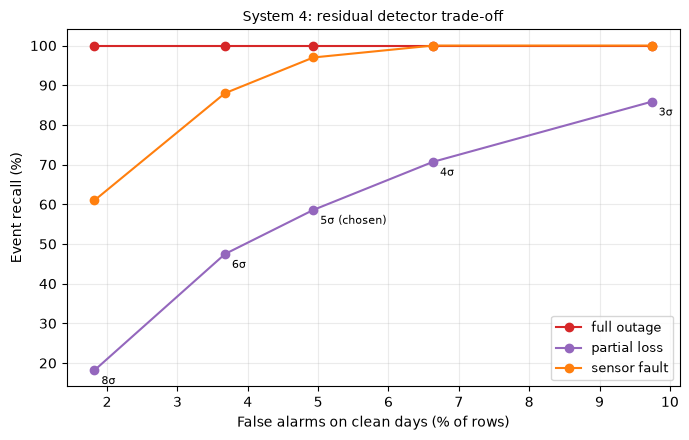

In [11]:
MAD_FACTORS = [3, 4, 5, 6, 8]
sensitivity_rows = []
for factor in MAD_FACTORS:
    low = RESIDUAL_CENTER - factor * RESIDUAL_SIGMA
    high = RESIDUAL_CENTER + factor * RESIDUAL_SIGMA
    flag = event_flags["rel_residual_smooth"].lt(low) | event_flags["rel_residual_smooth"].gt(high)
    covered = flag.groupby(event_flags["event"]).mean().ge(MIN_EVENT_COVERAGE)
    detected = events_injected.join(covered.rename("detected"), on="event")
    false_alarm = untouched_smooth.lt(low) | untouched_smooth.gt(high)
    row = {"mad_factor": factor, "low_threshold": low, "high_threshold": high,
           "false_alarm_%": 100 * false_alarm.mean()}
    row |= {f"{kind}_recall_%": 100 * detected.loc[detected["type"].eq(kind), "detected"].mean()
            for kind in ANOMALY_TYPES}
    sensitivity_rows.append(row)
sensitivity = pd.DataFrame(sensitivity_rows).set_index("mad_factor")
sensitivity.to_csv(METRICS_DIR / f"system_{SYSTEM_ID}_anomaly_residual_sensitivity.csv")
display(sensitivity.round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
for kind, color in zip(ANOMALY_TYPES, ("tab:red", "tab:purple", "tab:orange")):
    ax.plot(sensitivity["false_alarm_%"], sensitivity[f"{kind}_recall_%"], marker="o", color=color, label=kind)
for factor, row in sensitivity.iterrows():
    ax.annotate(f"{factor:g}σ" + (" (chosen)" if factor == RESIDUAL_MAD_FACTOR else ""),
                (row["false_alarm_%"], row["partial loss_recall_%"]), xytext=(5, -10),
                textcoords="offset points", fontsize=8)
ax.set_xlabel("False alarms on clean days (% of rows)")
ax.set_ylabel("Event recall (%)")
ax.set_title(f"System {SYSTEM_ID}: residual detector trade-off", fontsize=10)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(METRICS_DIR / f"system_{SYSTEM_ID}_anomaly_residual_sensitivity.png", dpi=160)
plt.show()

## 5.6 Agreement analysis (F6)

Where do the detectors agree (confident anomalies) and where do they disagree? Each test row gets a pattern of the three detectors (rule / residual / Isolation Forest). For every pattern the table shows how many rows it has and what they look like: median irradiance, median actual / expected power, the most common months. Rows flagged by all three are confident anomalies; the residual-only rows are the candidates for partial losses and sensor faults that the rule cannot see.

In [12]:
pattern = (test_flags["rule"].map({True: "R", False: "-"})
           + test_flags["residual"].map({True: "S", False: "-"})
           + test_flags["iforest"].map({True: "I", False: "-"}))
PATTERN_NAMES = {"RSI": "all three", "RS-": "rule + residual", "R-I": "rule + iforest", "-SI": "residual + iforest",
                 "R--": "rule only", "-S-": "residual only", "--I": "iforest only", "---": "none"}
power_ratio = test[TARGET] / test["expected"].clip(lower=MIN_EXPECTED_SHARE * P_REF)


def top_months(months):
    return ", ".join(str(m) for m in months.value_counts().index[:3])


agreement = pd.DataFrame({
    "rows": pattern.value_counts(),
    "median_irradiance": test[IRRADIANCE].groupby(pattern).median(),
    "median_actual_over_expected": power_ratio.groupby(pattern).median(),
    "share_residual_high_%": 100 * test_flags["residual_high"].groupby(pattern).mean(),
    "top_months": pd.Series(test.index.month, index=test.index).groupby(pattern).apply(top_months),
}).rename(index=PATTERN_NAMES)
agreement["share_%"] = 100 * agreement["rows"] / len(test)
agreement = agreement.sort_values("rows", ascending=False)
AGREEMENT_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_anomaly_agreement.csv"
agreement.to_csv(AGREEMENT_PATH)
display(agreement.round(3))

residual_only = pattern.eq("-S-")
print("Residual-only rows by month (% of that month's test rows):")
display((100 * residual_only.groupby(test.index.month).mean()).round(2).rename("residual_only_%").to_frame().T)
print(f"Saved to: {AGREEMENT_PATH}")

,rows,median_irradiance,median_actual_over_expected,share_residual_high_%,top_months,share_%
none,249996,576.291,0.984,0.000,"3, 1, 2",88.182
residual only,12931,196.339,0.715,10.943,"7, 3, 6",4.561
all three,10717,371.267,0.031,0.000,"2, 1, 3",3.780
rule + residual,7075,91.453,0.224,0.000,"3, 1, 4",2.496
iforest only,1561,1239.785,0.985,0.000,"3, 4, 2",0.551
rule only,700,179.419,0.294,0.000,"2, 1, 11",0.247
residual + iforest,377,1157.260,0.659,3.183,"12, 2, 1",0.133
rule + iforest,142,318.148,0.115,0.000,"11, 10, 12",0.050


Residual-only rows by month (% of that month's test rows):


datetime,1,2,3,4,5,6,7,8,9,10,11,12
residual_only_%,2.82,4.11,3.92,6.33,5.57,5.98,6.96,5.11,3.95,2.92,3.07,6.67


Saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/metrics/system_4_anomaly_agreement.csv


## 5.7 Example events over time (F7)

Four test days chosen automatically: the **longest rule event**, a day with **short rule events** (single minutes to a few minutes), the day with the most **residual-only low** minutes (partial-loss candidate) and the day with the most **residual-high** minutes (sensor-fault candidate). Each panel shows the actual and expected power, the irradiance (right axis), and one marker row per detector.

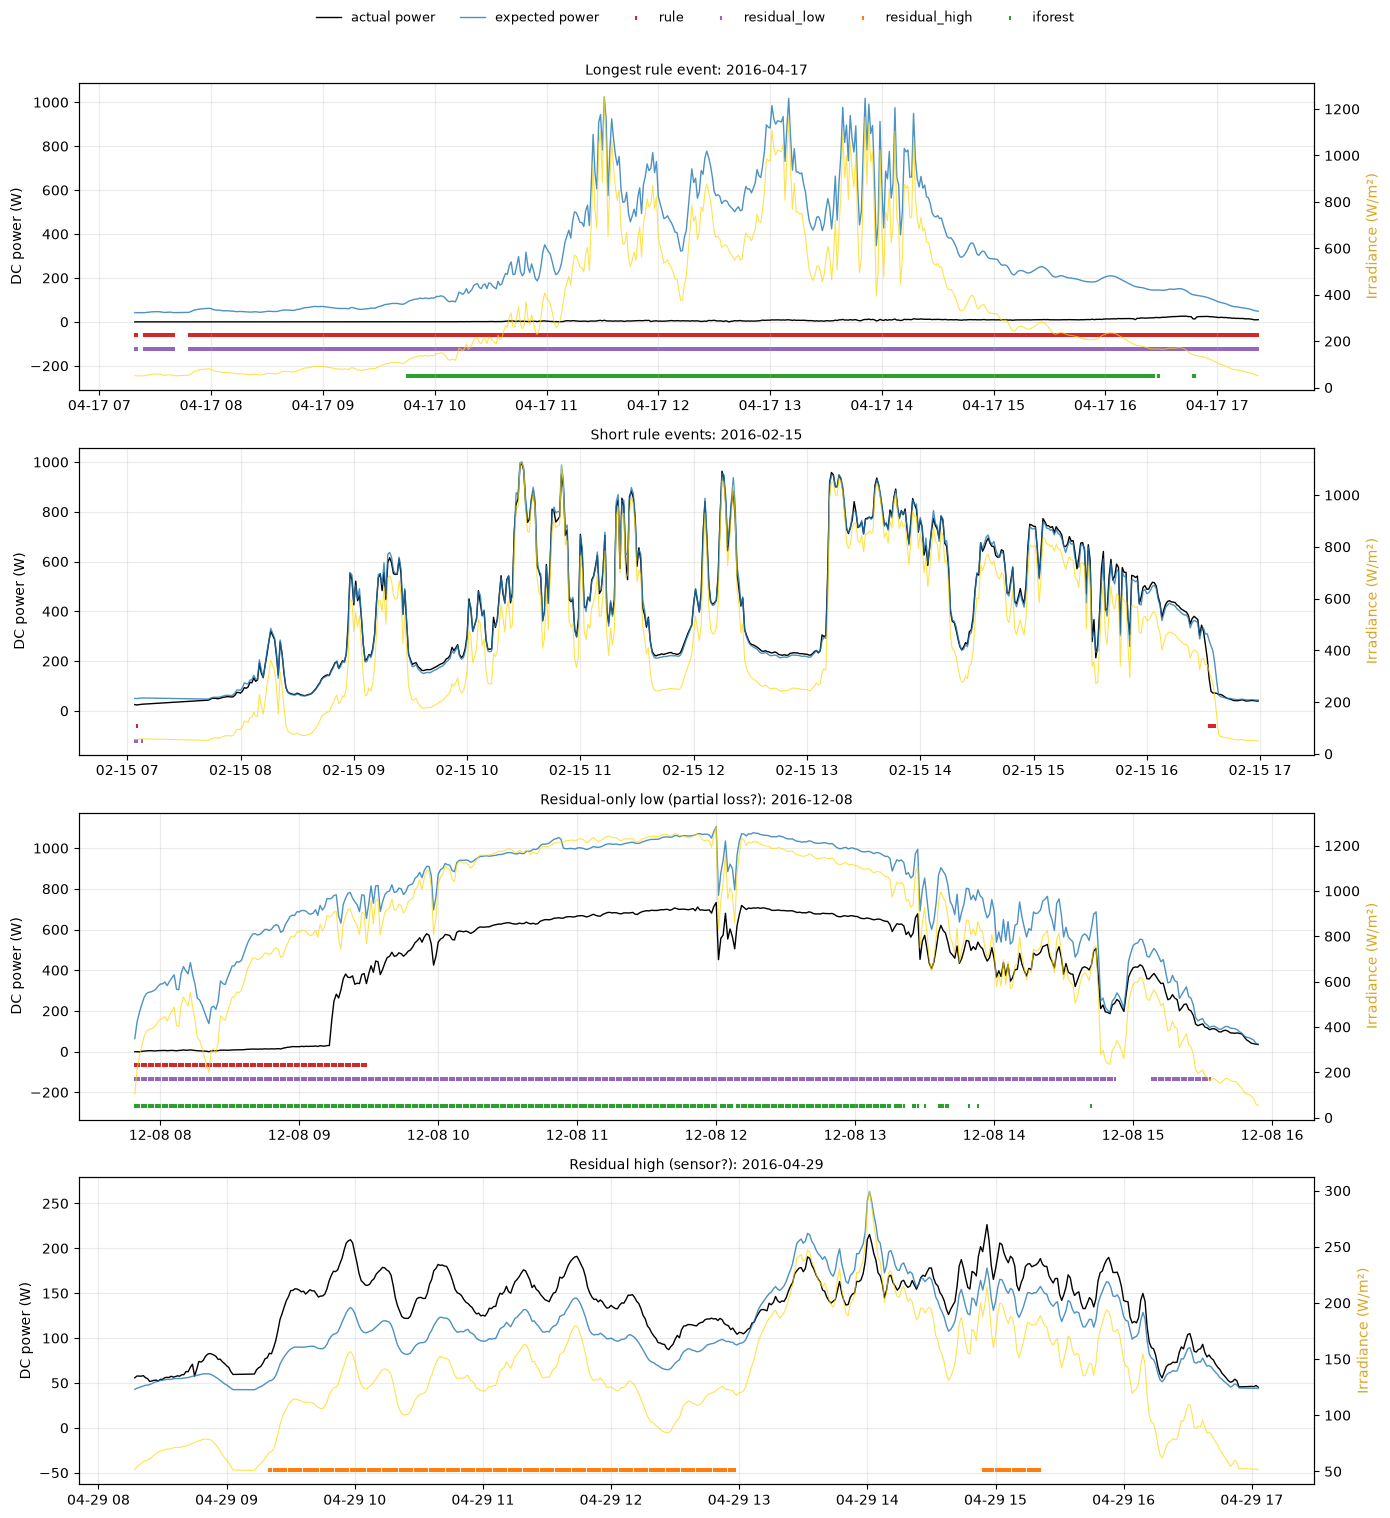

{'Longest rule event': '2016-04-17', 'Short rule events': '2016-02-15', 'Residual-only low (partial loss?)': '2016-12-08', 'Residual high (sensor?)': '2016-04-29'}
Event durations in the test period (minutes):


,count,50%,90%,max
rule,452.0,13.0,99.0,604.0
residual_low,486.0,34.5,100.5,604.0
residual_high,23.0,28.0,191.6,219.0
iforest,323.0,8.0,143.8,594.0


Saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/metrics/system_4_anomaly_examples.png


In [13]:
rule_events = to_events(test_flags["rule"])
low_only = test_flags["residual_low"] & ~test_flags["rule"]
example_days = {}
if len(rule_events):
    example_days["Longest rule event"] = rule_events.loc[rule_events["minutes"].idxmax(), "start"].normalize()
    short = rule_events[rule_events["minutes"].le(5)]
    if len(short):
        example_days["Short rule events"] = short["start"].dt.normalize().value_counts().idxmax()
if low_only.any():
    example_days["Residual-only low (partial loss?)"] = low_only.groupby(test.index.normalize()).sum().idxmax()
if test_flags["residual_high"].any():
    example_days["Residual high (sensor?)"] = test_flags["residual_high"].groupby(test.index.normalize()).sum().idxmax()

EXAMPLES_PLOT_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_anomaly_examples.png"
fig, axes = plt.subplots(len(example_days), 1, figsize=(14, 3.8 * len(example_days)), squeeze=False)
for ax, (label, example_day) in zip(axes[:, 0], example_days.items()):
    window = test.loc[example_day: example_day + pd.Timedelta(hours=23, minutes=59)]
    window_flags = test_flags.loc[window.index]
    ax.plot(window.index, window[TARGET], color="black", linewidth=1, label="actual power")
    ax.plot(window.index, window["expected"], color="tab:blue", linewidth=1, alpha=0.8, label="expected power")
    irradiance_ax = ax.twinx()
    irradiance_ax.plot(window.index, window[IRRADIANCE], color="gold", linewidth=0.8, alpha=0.7)
    irradiance_ax.set_ylabel("Irradiance (W/m²)", color="goldenrod")
    top = max(window[TARGET].max(), window["expected"].max())
    for level, detector in enumerate(("rule", "residual_low", "residual_high", "iforest")):
        flagged = window.index[window_flags[detector].to_numpy()]
        ax.scatter(flagged, np.full(len(flagged), -0.06 * top * (level + 1)), s=6, marker="|",
                   color=DETECTOR_COLORS[detector], label=detector)
    ax.set_title(f"{label}: {example_day.date()}", fontsize=10)
    ax.set_ylabel("DC power (W)")
    ax.grid(True, alpha=0.25)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=9, ncol=6, loc="upper center", frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(EXAMPLES_PLOT_PATH, dpi=160)
plt.show()

durations = pd.DataFrame({detector: to_events(test_flags[detector])["minutes"].describe(percentiles=[0.5, 0.9])
                          for detector in ("rule", "residual_low", "residual_high", "iforest")}).T
print({label: str(d.date()) for label, d in example_days.items()})
print("Event durations in the test period (minutes):")
display(durations[["count", "50%", "90%", "max"]].round(1))
print(f"Saved to: {EXAMPLES_PLOT_PATH}")

## 5.8 Summary for notebook 6

One table with the real-data results (5.5.1) and the synthetic event recall and false alarms (5.5.2), saved to `artifacts/metrics/system_<id>_anomaly_summary.csv`. The detector settings (k, thresholds, `P_REF`) are saved to `artifacts/models/system_<id>_anomaly_detector.json` for the local prediction app.

In [14]:
summary_rows = []
for detector in DETECTORS:
    row = {"system": SYSTEM_ID, "detector": detector, "reference_model": REFERENCE_MODEL,
           "test_flagged_%": real_table.loc[detector, "flagged_share_%"],
           "real_recall_full_outage_%": real_table.loc[detector, "recall_full_outage_%"],
           "real_flags_outside_rule_%": real_table.loc[detector, "flags_outside_rule_%"]}
    for kind in ANOMALY_TYPES:
        row[f"synthetic_{kind.replace(' ', '_')}_recall_%"] = synthetic_table.loc[(kind, detector), "event_recall_%"]
    row["synthetic_false_alarm_%"] = synthetic_table.loc[("false alarms (clean days)", detector), "row_recall_%"]
    row["synthetic_events_per_type"] = n_events
    row["synthetic_injection_days"] = len(injection_days)
    summary_rows.append(row)

anomaly_summary = pd.DataFrame(summary_rows).set_index("detector")
SUMMARY_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_anomaly_summary.csv"
anomaly_summary.to_csv(SUMMARY_PATH)
display(anomaly_summary.T.round(2))
print(f"Saved to: {SUMMARY_PATH}")

# Settings of the rule and residual detectors, for reuse outside the notebook (thesis/app).
DETECTOR_PATH = MODELS_DIR / f"system_{SYSTEM_ID}_anomaly_detector.json"
DETECTOR_PATH.write_text(json.dumps({
    "reference_model": REFERENCE_MODEL, "k": K, "fault_ratio": FAULT_RATIO,
    "fault_min_irradiance": FAULT_MIN_IRRADIANCE_W_M2, "p_ref": P_REF,
    "min_expected_share": MIN_EXPECTED_SHARE, "residual_center": RESIDUAL_CENTER,
    "residual_sigma": RESIDUAL_SIGMA, "residual_mad_factor": RESIDUAL_MAD_FACTOR,
    "low_threshold": LOW_THRESHOLD, "high_threshold": HIGH_THRESHOLD,
}, indent=2))
print(f"Detector settings saved to: {DETECTOR_PATH}")

detector,rule,residual,iforest
system,4,4,4
reference_model,MLP,MLP,MLP
test_flagged_%,6.572863,10.970056,4.513949
real_recall_full_outage_%,100.0,99.489607,78.294358
real_flags_outside_rule_%,0.0,42.790997,15.144174
synthetic_full_outage_recall_%,100.0,100.0,99.0
synthetic_partial_loss_recall_%,0.0,58.0,18.0
synthetic_sensor_fault_recall_%,0.0,97.0,19.0
synthetic_false_alarm_%,0.0,4.932129,0.821216
synthetic_events_per_type,100,100,100


Saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/metrics/system_4_anomaly_summary.csv
Detector settings saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/models/system_4_anomaly_detector.json


## 5.9 Single-reading bands (for the local app)

The local app checks **one** reading at a time, either against the endogenous model (irradiance and module temperature known) or, when only the date, time and ambient temperature are known, against the exogenous model (`best model` of notebook 4 for each task). The normal band of the **point** relative residual (no 15-minute median) is learned on the training-period normal rows:

- endogenous reference: median ± `RESIDUAL_MAD_FACTOR` robust σ, as in 5.3;
- exogenous reference: the `EXOGENOUS_BAND_QUANTILES` quantiles. Clouds make its errors very wide and skewed (σ about 8× larger), so a MAD band would reach below −100% and could never flag anything; the quantile band at least catches near-total outages.

For the endogenous reference the app also shows a **severity colour**, from the distance of the reading to the median in robust σ, at the levels studied in 5.5.3 (`SEVERITY_LEVELS`):

| Colour | Distance | Meaning (from the sensitivity table) |
|---|---|---|
| green | < 3σ | normal operation |
| yellow | 3-5σ | deviation to watch: 3σ already catches most partial losses, but with ~10% false alarms |
| orange | 5-8σ | fault: 5σ is the threshold of the residual detector |
| red | > 8σ | severe fault: 8σ is the strictest level tested (~2% false alarms); full outages land here |

The bands, σ and levels are added to `system_<id>_anomaly_detector.json`.

In [15]:
EXOGENOUS_BAND_QUANTILES = (0.005, 0.995)
SEVERITY_LEVELS = {"green": 3, "yellow": 5, "orange": 8}  # upper limit of each colour, in robust sigma
exogenous_model_name = best_models.loc["Estimation, exogenous", "chosen"]
with (MODELS_DIR / f"system_{SYSTEM_ID}_exogenous_{MODEL_SLUGS[exogenous_model_name]}.pkl").open("rb") as file:
    exogenous_model = pickle.load(file)
with (MODELS_DIR / f"scaler_group_{SYSTEM_ID}_exogenous.pkl").open("rb") as file:
    exogenous_scaler = pickle.load(file)

hour = data.index.hour + data.index.minute / 60
day_of_year = data.index.dayofyear - 1 + hour / 24
calendar = {"hour_sin": np.sin(2 * np.pi * hour / 24), "hour_cos": np.cos(2 * np.pi * hour / 24),
            "doy_sin": np.sin(2 * np.pi * day_of_year / 365.25), "doy_cos": np.cos(2 * np.pi * day_of_year / 365.25)}
exogenous_inputs = pd.DataFrame({column: data[column] if column in data else calendar[column]
                                 for column in exogenous_scaler.feature_names_in_}, index=data.index)
exogenous_expected = exogenous_model.predict(pd.DataFrame(exogenous_scaler.transform(exogenous_inputs),
                                                          index=data.index, columns=exogenous_inputs.columns))
floor = MIN_EXPECTED_SHARE * P_REF
point_residuals = {
    "endogenous": data.loc[train_normal, "rel_residual"],
    "exogenous": ((data[TARGET] - exogenous_expected) / np.maximum(exogenous_expected, floor))[train_normal],
}
center = float(point_residuals["endogenous"].median())
sigma = float(1.4826 * (point_residuals["endogenous"] - center).abs().median())
low_q, high_q = point_residuals["exogenous"].quantile(EXOGENOUS_BAND_QUANTILES)
single_reading = {
    "endogenous": {"model": REFERENCE_MODEL, "method": f"median ± {RESIDUAL_MAD_FACTOR:g} robust sigma",
                   "low": center - RESIDUAL_MAD_FACTOR * sigma, "high": center + RESIDUAL_MAD_FACTOR * sigma,
                   "center": center, "sigma": sigma, "severity_levels": SEVERITY_LEVELS},
    "exogenous": {"model": exogenous_model_name,
                  "method": f"{EXOGENOUS_BAND_QUANTILES[0]:.1%} / {EXOGENOUS_BAND_QUANTILES[1]:.1%} quantiles",
                  "low": float(low_q), "high": float(high_q)},
}
display(pd.DataFrame(single_reading).T[["model", "method", "low", "high"]])
print("Severity bands of the endogenous relative residual:")
display(pd.DataFrame({colour: {"below": center - level * sigma, "above": center + level * sigma}
                      for colour, level in SEVERITY_LEVELS.items()}).T.round(3))

detector_settings = json.loads(DETECTOR_PATH.read_text())
detector_settings["single_reading"] = single_reading
DETECTOR_PATH.write_text(json.dumps(detector_settings, indent=2))
print(f"Single-reading bands added to: {DETECTOR_PATH}")

,model,method,low,high
endogenous,MLP,median ± 5 robust sigma,-0.226982,0.243199
exogenous,MLP,0.5% / 99.5% quantiles,-0.884535,1.207888


Severity bands of the endogenous relative residual:


,below,above
green,-0.133,0.149
yellow,-0.227,0.243
orange,-0.368,0.384


Single-reading bands added to: /home/raul/Desktop/solar-data-all/thesis/artifacts/models/system_4_anomaly_detector.json
